In [5]:
import os
import json
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, Model
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

# Mixed precision speeds up training a lot on T4 GPUs
from tensorflow.keras import mixed_precision
mixed_precision.set_global_policy("mixed_float16")
print("Compute dtype policy:", mixed_precision.global_policy())

TensorFlow: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
Compute dtype policy: <DTypePolicy "mixed_float16">


In [6]:
DATASET_DIR = "/kaggle/input/datasets/moltean/fruits/fruits-360_100x100/fruits-360"

In [7]:
TRAIN_DIR = os.path.join(DATASET_DIR, "Training")
TEST_DIR = os.path.join(DATASET_DIR, "Test")

print("Training exists:", os.path.exists(TRAIN_DIR))
print("Test exists:", os.path.exists(TEST_DIR))

Training exists: True
Test exists: True


In [8]:
IMG_SIZE = (128, 128)
BATCH_SIZE = 128

SEED = 42

print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)
# NUM_CLASSES is set later, right after the dataset is loaded, so it always
# matches the real number of class folders found on disk.
#
# NOTE: native Fruits-360 images are 100x100. We use 128x128 (not 224x224)
# because upscaling small images to 224 costs real CPU time on every single
# image, every single epoch, for zero added detail (you can't get more
# resolution than the source image had). EfficientNetB0 works fine with
# smaller inputs for transfer learning - this cuts decode/resize/augmentation
# cost substantially and helps the GPU stop waiting on the CPU.

Image size: (128, 128)
Batch size: 128


In [9]:
AUTOTUNE = tf.data.AUTOTUNE

# Augmentation now runs as part of the model graph (on the GPU),
# instead of on the CPU like ImageDataGenerator did.
#
# Geometric + photometric augmentation. The brightness/contrast jitter and
# noise layers matter a lot for real-world photos: Fruits-360 images are all
# shot under identical studio lighting on a pure white background, so without
# this the model has never seen shadows, glare, warm/cool white balance, or
# camera sensor noise - all things a phone photo will have.

class AdditiveGaussianNoise(layers.Layer):
    # Keras's built-in GaussianNoise layer restricts stddev to [0, 1], which
    # assumes data already normalized to 0-1. Our images are 0-255 scale
    # (EfficientNetB0 expects raw pixel values), so stddev=8 out of 255 would
    # be forced down to ~0.03 and have basically no visible effect. This
    # small custom layer adds noise at the correct absolute scale, and (like
    # the built-in layer) only applies during training.
    def __init__(self, stddev, **kwargs):
        super().__init__(**kwargs)
        self.stddev = stddev

    def call(self, inputs, training=None):
        if training:
            noise = tf.random.normal(tf.shape(inputs), mean=0.0, stddev=self.stddev, dtype=inputs.dtype)
            return inputs + noise
        return inputs

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.20),
    layers.RandomTranslation(0.10, 0.10),
    layers.RandomBrightness(0.25, value_range=(0, 255)),
    layers.RandomContrast(0.25),
    AdditiveGaussianNoise(8.0),  # ~ mild sensor noise, on the correct 0-255 scale
], name="data_augmentation")

# NOTE: no manual Rescaling(1./255) here on purpose.
# EfficientNetB0 already includes its own Rescaling + Normalization layers
# internally (it expects raw 0-255 pixel values). Manually dividing by 255
# before feeding the model means those pixel values get divided by 255 a
# SECOND time inside EfficientNet, crushing the input toward zero and
# destroying almost all signal. That was the reason training loss was stuck
# exactly at ln(NUM_CLASSES) (~5.56 for 260 classes) - the model was
# essentially guessing uniformly at random from epoch 1 onward.

I0000 00:00:1789379303.644989      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1789379303.647947      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


In [10]:
# ---------------------------------------------------------------------------
# BACKGROUND COMPOSITING
# ---------------------------------------------------------------------------
# Every Fruits-360 image sits on a near-pure-white background. A model
# trained only on that will partly learn "white surroundings = valid object"
# as a shortcut, which does NOT hold for a real photo (kitchen counter,
# supermarket shelf, hand holding the fruit, etc). This step detects the
# white background per-pixel and replaces it with a different background on
# the fly during training, forcing the model to focus on the object itself.
#
# OPTIONAL - real backgrounds:
# If you add a Kaggle "textures" or "indoor scenes" dataset as an extra input
# (Add Data -> search "textures" or "DTD describable textures"), set
# BACKGROUND_DIR to its images folder below and real varied backgrounds will
# be used. If you leave it as None (or the path doesn't exist), synthetic
# backgrounds (solid colors / gradients / noise) are generated instead, which
# still helps a lot but is a weaker substitute for real photos.
BACKGROUND_DIR = None  # e.g. "/kaggle/input/dtd/dtd/images" - set if you add such a dataset

_background_files = None
if BACKGROUND_DIR is not None and os.path.isdir(BACKGROUND_DIR):
    _background_files = tf.io.gfile.glob(BACKGROUND_DIR + "/**/*.jpg")
    print(f"Using {len(_background_files)} real background images from {BACKGROUND_DIR}")
else:
    print("No BACKGROUND_DIR found - using synthetic (color/gradient/noise) backgrounds instead.")

if _background_files:
    _bg_path_tensor = tf.constant(_background_files)

def _load_random_real_background(size):
    idx = tf.random.uniform([], 0, len(_background_files), dtype=tf.int32)
    path = tf.gather(_bg_path_tensor, idx)
    img = tf.io.read_file(path)
    img = tf.io.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, size)
    return tf.cast(img, tf.float32)

def _make_synthetic_background(size):
    h, w = size[0], size[1]
    mode = tf.random.uniform([], 0, 3, dtype=tf.int32)

    color = tf.random.uniform([1, 1, 3], 0, 255)
    solid = tf.tile(color, [h, w, 1])

    grad_axis = tf.reshape(tf.linspace(0.0, 1.0, w), [1, w, 1])
    grad_axis = tf.tile(grad_axis, [h, 1, 3])
    c1 = tf.random.uniform([1, 1, 3], 0, 255)
    c2 = tf.random.uniform([1, 1, 3], 0, 255)
    gradient = c1 + (c2 - c1) * grad_axis

    noise = tf.random.uniform([h, w, 3], 0, 255)

    bg = tf.switch_case(mode, branch_fns={0: lambda: solid, 1: lambda: gradient, 2: lambda: noise})
    return tf.clip_by_value(bg, 0.0, 255.0)

def _replace_white_background(image, threshold=200.0):
    # image: float32, values in [0, 255], shape (H, W, 3)
    size = tf.shape(image)[:2]
    is_bg = tf.reduce_all(image > threshold, axis=-1, keepdims=True)
    is_bg = tf.cast(is_bg, tf.float32)

    if _background_files:
        new_bg = _load_random_real_background(size)
    else:
        new_bg = _make_synthetic_background(size)

    return image * (1.0 - is_bg) + new_bg * is_bg

def background_swap(image, p=0.5):
    return tf.cond(
        tf.random.uniform([]) < p,
        lambda: _replace_white_background(image),
        lambda: image
    )

def background_swap_batch(x, y, p=0.5):
    x = tf.map_fn(lambda img: background_swap(img, p=p), x)
    return x, y

No BACKGROUND_DIR found - using synthetic (color/gradient/noise) backgrounds instead.


In [11]:
train_ds_raw = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    validation_split=0.15,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=True
)

Found 138642 files belonging to 262 classes.
Using 117846 files for training.


In [12]:
val_ds_raw = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    validation_split=0.15,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=False
)

Found 138642 files belonging to 262 classes.
Using 20796 files for validation.


In [13]:
test_ds_raw = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=False
)

Found 46196 files belonging to 262 classes.


In [14]:
class_names = train_ds_raw.class_names

# IMPORTANT: derive NUM_CLASSES from the actual data instead of hardcoding it.
# The dataset folder can have a slightly different class count than expected
# (e.g. 260 vs the assumed 262), and a mismatch here causes:
# "ValueError: Arguments `target` and `output` must have the same shape"
# when the model's output layer size does not match the real label depth.
NUM_CLASSES = len(class_names)

print("Training batches:", tf.data.experimental.cardinality(train_ds_raw).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds_raw).numpy())
print("Test batches:", tf.data.experimental.cardinality(test_ds_raw).numpy())
print("Classes (actual):", NUM_CLASSES)

Training batches: 921
Validation batches: 163
Test batches: 361
Classes (actual): 262


In [15]:
print(class_names[:10])
print("Number of classes:", len(class_names))

['Almonds 1', 'Apple 10', 'Apple 11', 'Apple 12', 'Apple 13', 'Apple 14', 'Apple 17', 'Apple 18', 'Apple 19', 'Apple 20']
Number of classes: 262


In [16]:
with open("class_names.json", "w") as f:
    json.dump(class_names, f)

print("Class names saved.")

Class names saved.


In [17]:
def prepare(ds, training=False, cache=False):
    # Images from image_dataset_from_directory come as raw 0-255 float32
    # pixel values - feed them straight to the model as-is. Do NOT rescale
    # to 0-1 here; EfficientNetB0 does its own rescaling/normalization
    # internally and expects 0-255 input.
    if training:
        # Swap the white studio background for something else ~50% of the
        # time BEFORE geometric/photometric augmentation, so the model stops
        # associating "white surroundings" with "this is the object".
        ds = ds.map(lambda x, y: background_swap_batch(x, y, p=0.5),
                     num_parallel_calls=AUTOTUNE)
        ds = ds.map(lambda x, y: (data_augmentation(x, training=True), y),
                     num_parallel_calls=AUTOTUNE)
    # NOTE: no extra .shuffle() here on purpose.
    # image_dataset_from_directory() already shuffles file order when reading
    # (shuffle=True by default). Calling .shuffle(N) AFTER batching would try
    # to buffer N full batches in RAM at once (N=1000 * batch=128 images *
    # 128x128x3 float32 is still tens of GB) - that is what was climbing the
    # RAM to the session limit even after removing .cache().
    #
    # NOTE: do NOT use in-memory .cache() on the full training/validation sets
    # either - 117,978 images is tens of GB, which crashes the notebook
    # ("tried to allocate more memory than is available").
    # If you want caching, cache to disk instead: ds.cache("/kaggle/working/train_cache")
    if cache:
        ds = ds.cache()
    return ds.prefetch(AUTOTUNE)

train_ds = prepare(train_ds_raw, training=True, cache=False)
val_ds = prepare(val_ds_raw, training=False, cache=False)
test_ds = prepare(test_ds_raw, training=False, cache=False)

print("Pipelines ready.")

Pipelines ready.


In [18]:
# (Removed: this was a duplicate of the base_model/model definition below -
# it was loading EfficientNetB0 ImageNet weights a second time for no reason,
# wasting time and memory. The real model is built in the next cell.)

In [19]:
input_shape = IMG_SIZE + (3,)

base_model = EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=input_shape
)

base_model.trainable = False

inputs = layers.Input(shape=input_shape)

x = base_model(inputs, training=False)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dropout(0.3)(x)

x = layers.Dense(256, activation="relu")(x)

x = layers.Dropout(0.2)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax",
    dtype="float32"  # keep final layer in float32 for numerical stability with mixed precision
)(x)

model = Model(inputs, outputs)

model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 4, 4, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 262)            │        67,334 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,444,841 (16.96 MB)

 Trainable params: 395,270 (1.51 MB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [20]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [21]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

checkpoint = ModelCheckpoint(
    "best_fruits_model.keras",
    monitor="val_accuracy",
    save_best_only=True,
    verbose=1
)

In [22]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[
        early_stopping,
        reduce_lr,
        checkpoint
    ]
)

Epoch 1/15


I0000 00:00:1789379600.280007     132 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


921/921 ━━━━━━━━━━━━━━━━━━━━ 0s 743ms/step - accuracy: 0.4344 - loss: 2.5203
Epoch 1: val_accuracy improved from None to 0.83430, saving model to best_fruits_model.keras

Epoch 1: finished saving model to best_fruits_model.keras
921/921 ━━━━━━━━━━━━━━━━━━━━ 819s 825ms/step - accuracy: 0.5989 - loss: 1.5565 - val_accuracy: 0.8343 - val_loss: 0.5321 - learning_rate: 0.0010
Epoch 2/15
920/921 ━━━━━━━━━━━━━━━━━━━━ 0s 517ms/step - accuracy: 0.7595 - loss: 0.7842
Epoch 2: val_accuracy improved from 0.83430 to 0.86286, saving model to best_fruits_model.keras

Epoch 2: finished saving model to best_fruits_model.keras
921/921 ━━━━━━━━━━━━━━━━━━━━ 494s 535ms/step - accuracy: 0.7709 - loss: 0.7387 - val_accuracy: 0.8629 - val_loss: 0.3955 - learning_rate: 0.0010
Epoch 3/15
920/921 ━━━━━━━━━━━━━━━━━━━━ 0s 540ms/step - accuracy: 0.7993 - loss: 0.6399
Epoch 3: val_accuracy improved from 0.86286 to 0.90051, saving model to best_fruits_model.keras

Epoch 3: finished saving model to best_fruits_model.k

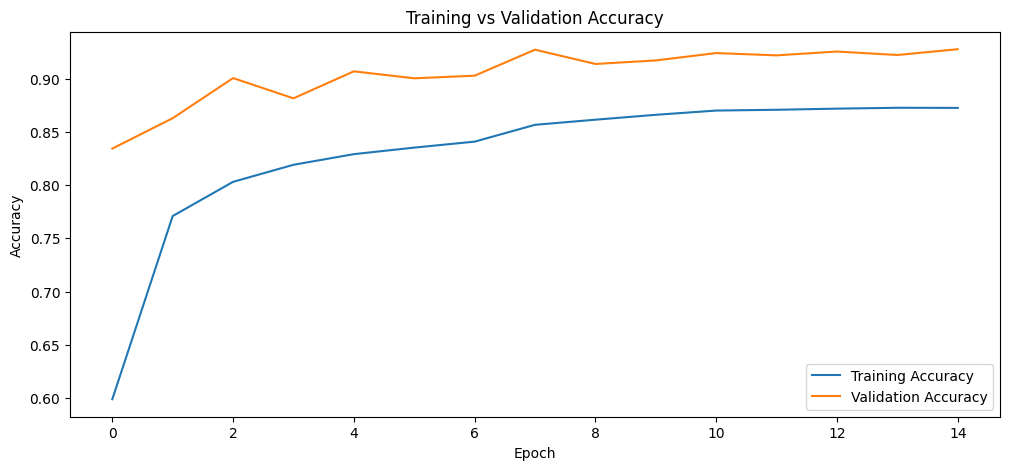

In [23]:
plt.figure(figsize=(12, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.show()

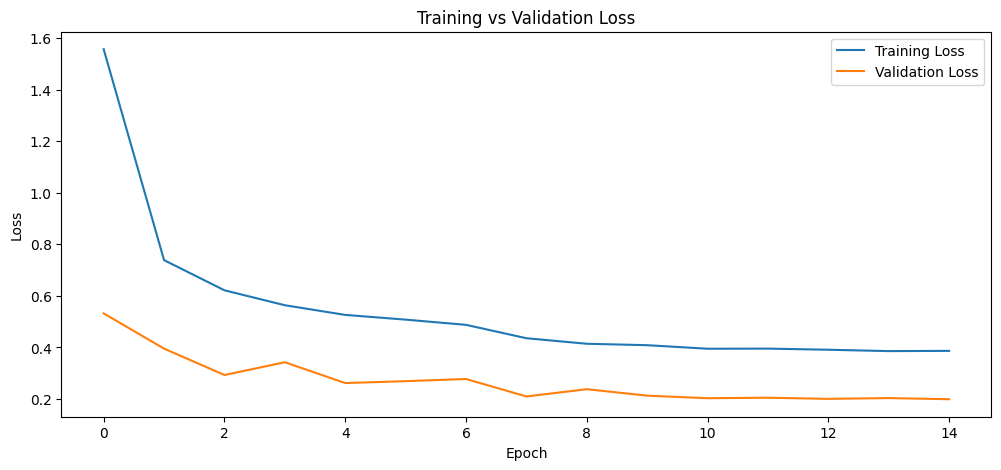

In [24]:
plt.figure(figsize=(12, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.show()

In [25]:
model = tf.keras.models.load_model(
    "best_fruits_model.keras"
)

print("Best model loaded.")

Best model loaded.


In [26]:
test_loss, test_accuracy = model.evaluate(
    test_ds,
    verbose=1
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

361/361 ━━━━━━━━━━━━━━━━━━━━ 215s 541ms/step - accuracy: 0.8781 - loss: 0.5005
Test Loss: 0.5005
Test Accuracy: 0.8781


In [27]:
predictions = model.predict(
    test_ds,
    verbose=1
)

y_pred = np.argmax(predictions, axis=1)
y_true = np.concatenate([y.numpy() for _, y in test_ds_raw], axis=0).argmax(axis=1)

361/361 ━━━━━━━━━━━━━━━━━━━━ 65s 131ms/step


In [28]:
print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        zero_division=0
    )
)

                        precision    recall  f1-score   support

             Almonds 1       1.00      0.91      0.95        77
              Apple 10       0.95      0.75      0.84       231
              Apple 11       0.86      0.92      0.88       142
              Apple 12       1.00      0.49      0.66       154
              Apple 13       0.98      0.83      0.90       235
              Apple 14       0.91      0.81      0.86       154
              Apple 17       1.00      0.53      0.69       201
              Apple 18       0.97      0.79      0.87       240
              Apple 19       0.95      1.00      0.98       241
              Apple 20       0.93      0.93      0.93       234
              Apple 21       0.81      1.00      0.90       162
              Apple 22       0.98      0.78      0.87       231
              Apple 23       1.00      1.00      1.00       156
               Apple 5       0.76      0.71      0.74       146
               Apple 6       0.96      

In [29]:
cm = confusion_matrix(
    y_true,
    y_pred
)

print("Confusion Matrix Shape:", cm.shape)

Confusion Matrix Shape: (262, 262)


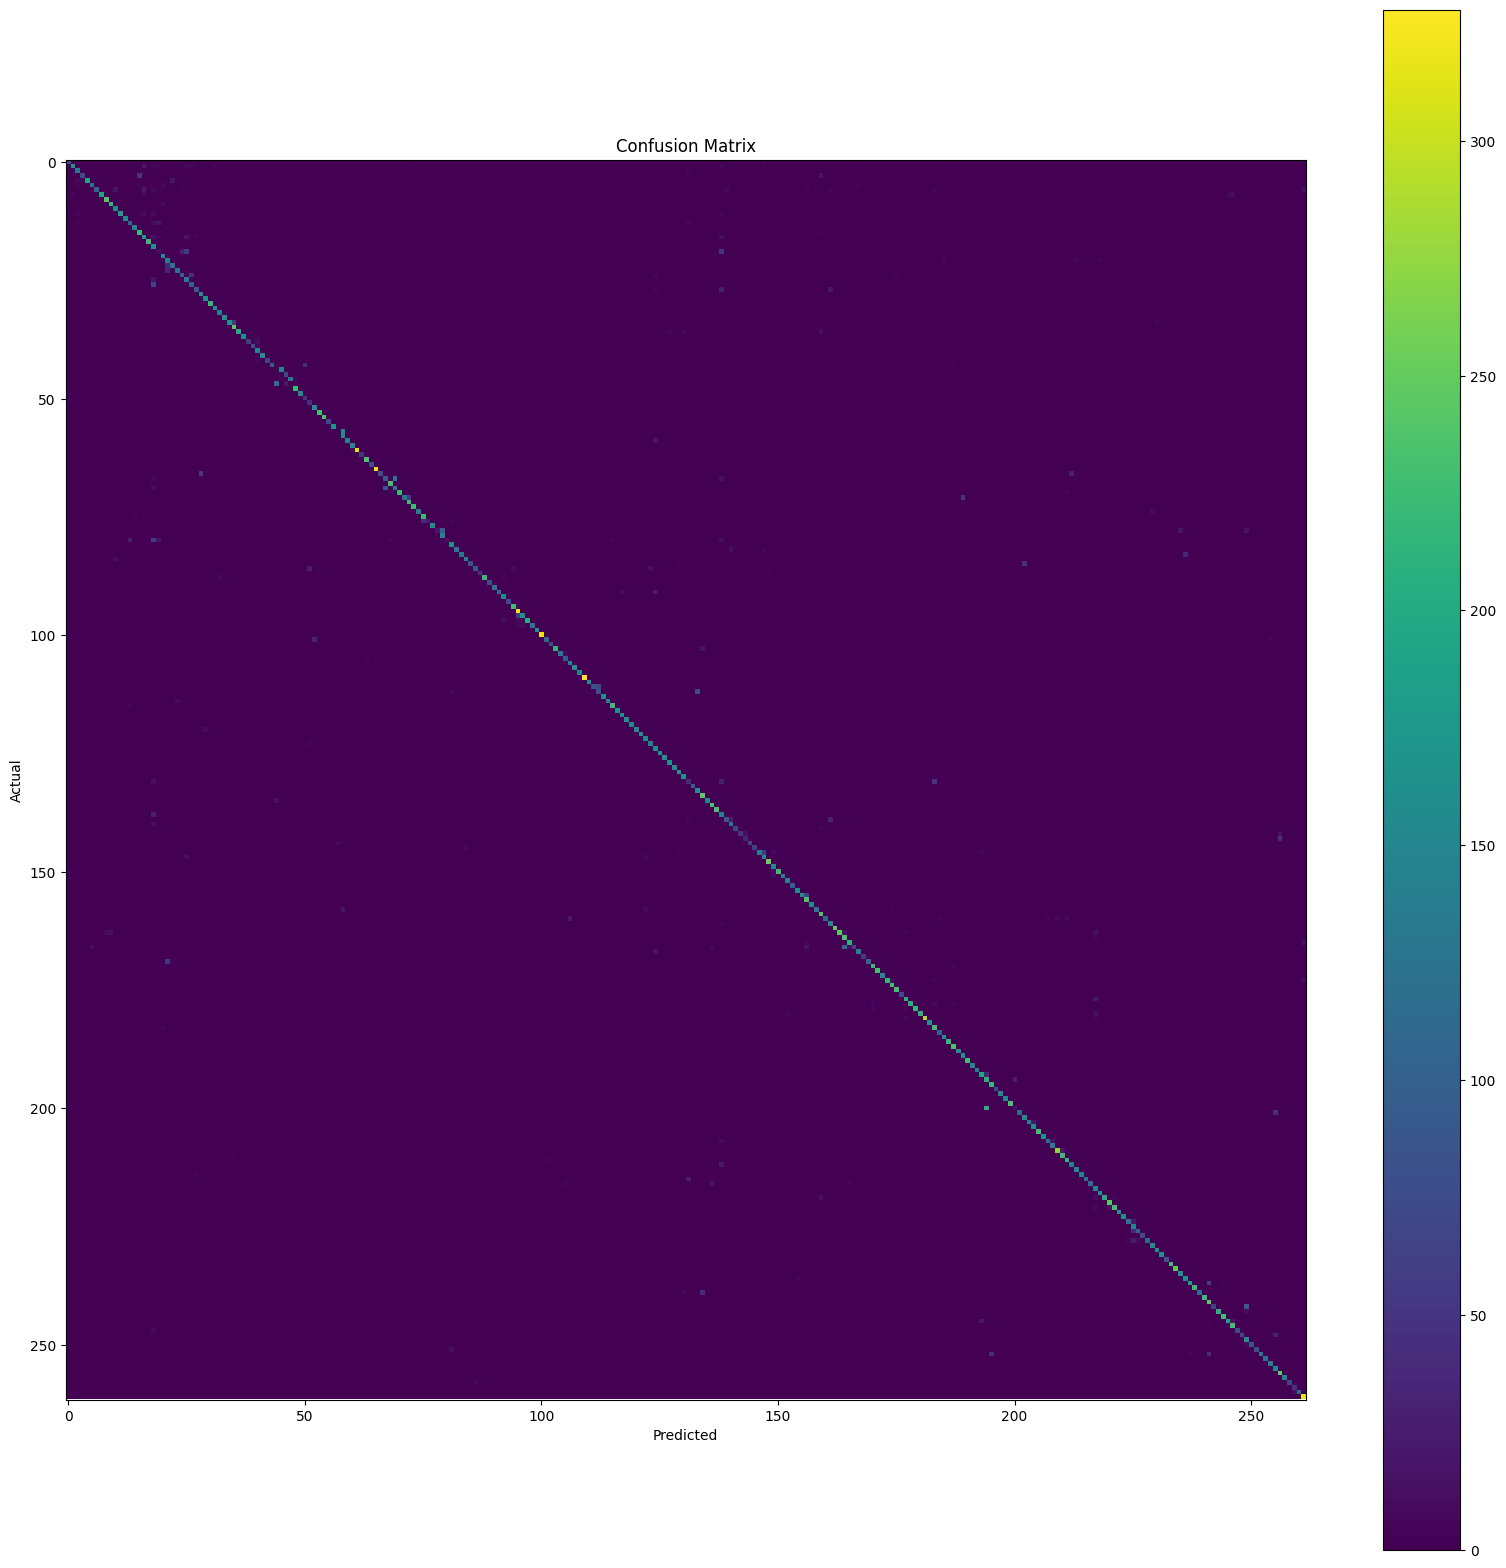

In [30]:
plt.figure(figsize=(20, 20))

plt.imshow(cm)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.colorbar()

plt.show()

In [31]:
base_model.trainable = True

In [32]:
for layer in base_model.layers[:-30]:
    layer.trainable = False

In [33]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [34]:
fine_tune_history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[
        early_stopping,
        reduce_lr,
        checkpoint
    ]
)

Epoch 1/10
921/921 ━━━━━━━━━━━━━━━━━━━━ 0s 566ms/step - accuracy: 0.8715 - loss: 0.3911
Epoch 1: val_accuracy did not improve from 0.92763
921/921 ━━━━━━━━━━━━━━━━━━━━ 608s 622ms/step - accuracy: 0.8724 - loss: 0.3865 - val_accuracy: 0.9269 - val_loss: 0.1992 - learning_rate: 1.0000e-05
Epoch 2/10
920/921 ━━━━━━━━━━━━━━━━━━━━ 0s 531ms/step - accuracy: 0.8737 - loss: 0.3859
Epoch 2: ReduceLROnPlateau reducing learning rate to 1.9999999494757505e-06.

Epoch 2: val_accuracy did not improve from 0.92763
921/921 ━━━━━━━━━━━━━━━━━━━━ 507s 549ms/step - accuracy: 0.8742 - loss: 0.3851 - val_accuracy: 0.9262 - val_loss: 0.2002 - learning_rate: 1.0000e-05
Epoch 3/10
920/921 ━━━━━━━━━━━━━━━━━━━━ 0s 534ms/step - accuracy: 0.8716 - loss: 0.3873
Epoch 3: val_accuracy did not improve from 0.92763
921/921 ━━━━━━━━━━━━━━━━━━━━ 511s 553ms/step - accuracy: 0.8728 - loss: 0.3858 - val_accuracy: 0.9261 - val_loss: 0.2002 - learning_rate: 2.0000e-06
Epoch 4/10
921/921 ━━━━━━━━━━━━━━━━━━━━ 0s 524ms/step - ac

In [35]:
model = tf.keras.models.load_model(
    "best_fruits_model.keras"
)

In [36]:
test_loss, test_accuracy = model.evaluate(
    test_ds,
    verbose=1
)

print(f"Final Test Accuracy: {test_accuracy:.4f}")

361/361 ━━━━━━━━━━━━━━━━━━━━ 76s 155ms/step - accuracy: 0.8781 - loss: 0.5005
Final Test Accuracy: 0.8781


In [37]:
model.save("model.h5")

In [38]:
model.save("fruits360_efficientnetb0.keras")

print("Model saved successfully.")

Model saved successfully.
